29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Veri setleri başarıyla yüklendi ve normalize edildi.

---> Model 10 Epoch için eğitiliyor...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Sonuç (10 Epoch): Test Doğruluğu (Accuracy) = 0.8838 | Test Kaybı (Loss) = 0.3405

---> Model 20 Epoch için eğitiliyor...
Sonuç (20 Epoch): Test Doğruluğu (Accuracy) = 0.8796 | Test Kaybı (Loss) = 0.3850

---> Model 30 Epoch için eğitiliyor...
Sonuç (30 Epoch): Test Doğruluğu (Accuracy) = 0.8842 | Test Kaybı (Loss) = 0.4161


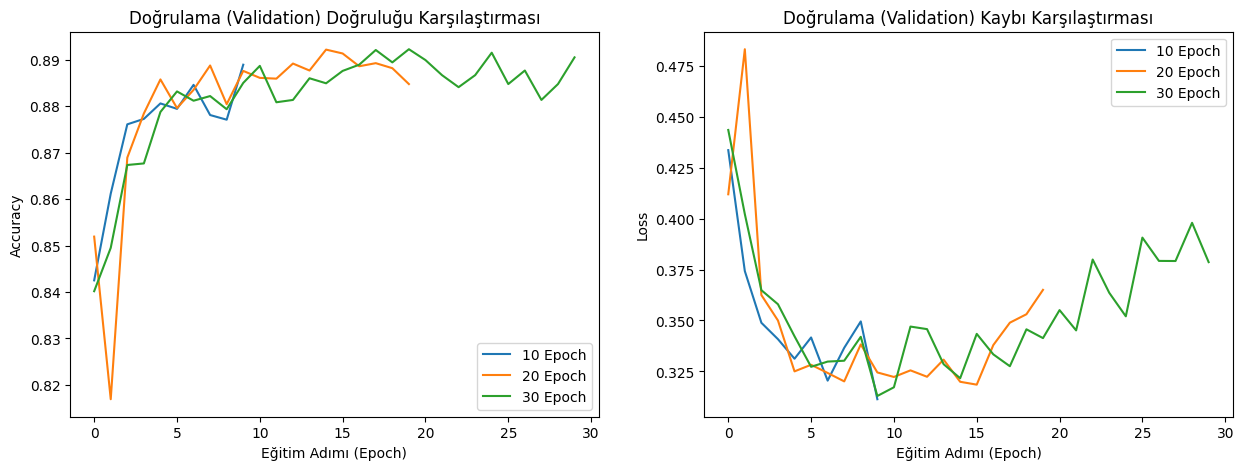

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


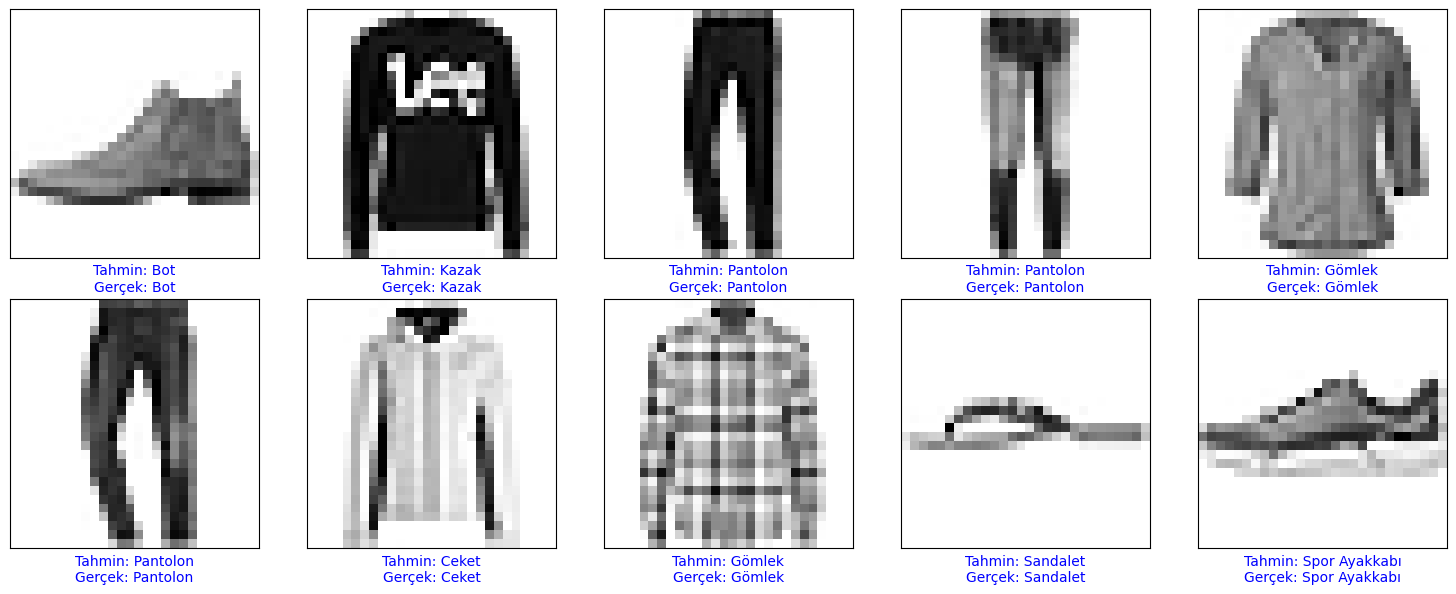

In [ ]:
# ==========================================
# Adı Soyadı: Hüseyin Ahmet Altun
# Öğrenci Numarası: 25019921034
# Bölüm: Yapay Zeka Operatörlüğü
# Proje: Fashion-MNIST Görüntü Sınıflandırma
# ==========================================

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# 1. VERİ SETİ SEÇİMİ VE YÜKLENMESİ
# Moda ürünlerinden oluşan veri setini yüklüyoruz
fashion_mnist = tf.keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

# Çıktı olarak alacağımız 10 farklı kıyafet sınıfı
class_names = ['Tişört/Üst', 'Pantolon', 'Kazak', 'Elbise', 'Ceket',
               'Sandalet', 'Gömlek', 'Spor Ayakkabı', 'Çanta', 'Bot']

# Normalizasyon: Piksel değerlerini 0-255 aralığından 0-1 aralığına çekiyoruz
train_images = train_images / 255.0
test_images = test_images / 255.0

print("Veri setleri başarıyla yüklendi ve normalize edildi.")

# 2. MODEL OLUŞTURMA FONKSİYONU
def model_olustur():
    model = tf.keras.Sequential([
        tf.keras.layers.Flatten(input_shape=(28, 28)),      # 28x28 görüntüleri düzleştirir
        tf.keras.layers.Dense(128, activation='relu'),      # Gizli katman
        tf.keras.layers.Dense(10, activation='softmax')     # 10 farklı sınıf için çıktı katmanı
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# 3. FARKLI EPOCH DEĞERLERİYLE EĞİTİM VE KARŞILAŞTIRMA
epoch_degerleri = [10, 20, 30]
egitim_gecmisleri = {}
modeller = {}

for epoch in epoch_degerleri:
    print(f"\n---> Model {epoch} Epoch için eğitiliyor...")
    model = model_olustur()
    # Modeli eğitiyoruz (verbose=0 yaparak ekranda çok fazla gereksiz satır çıkmasını engelliyoruz)
    history = model.fit(train_images, train_labels, epochs=epoch, validation_split=0.2, verbose=0)

    # Test verisiyle doğruluk testi
    test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)
    print(f"Sonuç ({epoch} Epoch): Test Doğruluğu (Accuracy) = {test_acc:.4f} | Test Kaybı (Loss) = {test_loss:.4f}")

    egitim_gecmisleri[epoch] = history
    modeller[epoch] = model

# 4. LOSS (KAYIP) VE ACCURACY (DOĞRULUK) GRAFİKLERİ
plt.figure(figsize=(15, 5))

# Doğruluk (Accuracy) Grafiği
plt.subplot(1, 2, 1)
for epoch in epoch_degerleri:
    # Hem eğitim hem de doğrulama verilerini grafiğe ekliyoruz
    plt.plot(egitim_gecmisleri[epoch].history['val_accuracy'], label=f'{epoch} Epoch')
plt.title('Doğrulama (Validation) Doğruluğu Karşılaştırması')
plt.xlabel('Eğitim Adımı (Epoch)')
plt.ylabel('Accuracy')
plt.legend()

# Kayıp (Loss) Grafiği
plt.subplot(1, 2, 2)
for epoch in epoch_degerleri:
    plt.plot(egitim_gecmisleri[epoch].history['val_loss'], label=f'{epoch} Epoch')
plt.title('Doğrulama (Validation) Kaybı Karşılaştırması')
plt.xlabel('Eğitim Adımı (Epoch)')
plt.ylabel('Loss')
plt.legend()

plt.show()

# 5. TAHMİNLER VE GÖRSELLEŞTİRME
# Hocanın istediği görselleştirme kısmı için en iyi eğitilmiş olan 30 Epoch modelini kullanalım
en_iyi_model = modeller[30]
tahminler = en_iyi_model.predict(test_images)

# Rastgele 10 görüntünün gerçek ve tahmin edilen sınıflarını ekrana bastıralım
plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i], cmap=plt.cm.binary)

    tahmin_edilen = np.argmax(tahminler[i])
    gercek = test_labels[i]

    # Doğru tahminleri mavi, yanlış tahminleri kırmızı renkte gösterelim
    renk = 'blue' if tahmin_edilen == gercek else 'red'
    plt.xlabel(f"Tahmin: {class_names[tahmin_edilen]}\nGerçek: {class_names[gercek]}", color=renk)

plt.tight_layout()
plt.show()